In [1]:
from pathlib import Path
import pandas as pd

project_dirc = Path(".")#. 表示 Notebook 当前的工作目录。沿用你已有的变量名 project_dirc。
#只是给这个路径起一个方便使用的变量名。以后不用每次输入整段路径。

# read TFP
tfp = pd.read_excel(
    project_dirc / "TFP.xlsx",
    sheet_name = "MachineReadable" #单独写时，是赋值：写在函数括号里面时，是传入参数： 真正执行读取的是 pd.read_excel(...)
)
#

# read sp500 
sp500 = pd.read_csv(
    project_dirc / "sp500_TR.csv"
)

tfp.shape：获取数据表的大小，结果格式为 (行数, 列数)。
中间的逗号：把说明文字与结果分开，交给 print 一起输出。
注意：.shape 后面没有括号，与 .head() 写法不同。

下一步，**确认整个 Notebook 能从头到尾独立运行**，避免它依赖之前保存在内存里的变量。

在 Notebook 顶部找到 **Restart（重启内核）**，然后选择 **Run All（运行全部）**；有些编辑器会合并成 **Restart & Run All**。

- **Restart**：清空内存中的变量。
- **Run All**：按照单元格从上到下的顺序重新运行代码。

运行前先按 **Command + S** 保存。注意，Notebook 中保存 CSV 的代码也会再次执行，覆盖同名输出文件，这是预期行为。

**如果遇到报错，先停在第一个报错处，把截图发给我。** 如果全部运行成功，再保存一次，保留更新后的输出。

In [2]:
display(tfp.head())
display(sp500.head())

print("TFP rownum, colnum", tfp.shape)
print("S&P 500 rownum, colnum", sp500.shape)



,NAICS,Sector,Basis,Measure,Units,Year,Value
0,XG,Private nonfarm business sector,All workers,Total factor productivity,Index (2017=100),1987,78.468
1,XG,Private nonfarm business sector,All workers,Real value-added output,Index (2017=100),1987,41.809
2,XG,Private nonfarm business sector,All workers,Combined inputs,Index (2017=100),1987,53.282
3,XG,Private nonfarm business sector,All workers,Capital input,Index (2017=100),1987,35.29
4,XG,Private nonfarm business sector,All workers,Labor input,Index (2017=100),1987,65.941


,Date,Open,High,Low,Close,Adj Close,Volume
0,1988-10-03,279.09,279.09,279.09,279.09,279.09,NaN
1,1988-10-04,278.35,278.35,278.35,278.35,278.35,NaN
2,1988-10-05,279.62,279.62,279.62,279.62,279.62,NaN
3,1988-10-06,280.17,280.17,280.17,280.17,280.17,NaN
4,1988-10-07,286.04,286.04,286.04,286.04,286.04,NaN


TFP rownum, colnum (4758, 7)
S&P 500 rownum, colnum (9569, 7)


Volume 中的 NaN 表示缺失值，因为原 PDF 这里是 -，不代表零。

feature 和 variable 并不是两种摆放位置。 在数据分析里，variable 是“变量”；在机器学习里，用来预测的输入变量常叫 feature（特征）。

建议年份单独作为一列，每一行代表一年：

每一行：一个观测，也就是某一年。
每一列：一个变量，例如年份、TFP 增长率、股市回报率



In [3]:
tfp['Sector'].unique()

array(['Private nonfarm business sector', 'Private business sector'],
      dtype=object)

tfp：你已经读取的数据表。

["Sector"]：取出“部门”这一列。
tfp["列名"] 用来取列，不能用行号直接取行
如果要按位置取某一行，用：tfp.iloc[0]
另外，tfp[条件] 也能筛选行

.unique()：列出这一列中不重复的值。同一个部门即使出现很多次，也只显示一次。

In [4]:
tfp_private = tfp[tfp["Sector"] == "Private business sector"]

display(tfp_private.head())

,NAICS,Sector,Basis,Measure,Units,Year,Value
61,PG,Private business sector,All workers,Total factor productivity,Index (2017=100),1987,77.368
62,PG,Private business sector,All workers,Real value-added output,Index (2017=100),1987,41.844
63,PG,Private business sector,All workers,Combined inputs,Index (2017=100),1987,54.084
64,PG,Private business sector,All workers,Capital input,Index (2017=100),1987,36.441
65,PG,Private business sector,All workers,Labor input,Index (2017=100),1987,66.642


外层 tfp[...]：只保留判断结果为 True 的行。

空括号表示使用默认设置：显示前 5 行。
head 是一个方法，后面的 () 表示“执行它”。
括号里可以放参数，告诉它显示多少行：

In [5]:
#在已经选好的私人企业部门中，只保留 TFP 这个指标

tfp_only = tfp_private[tfp_private["Measure"] == "Total factor productivity"]
#这一行的意思是：从 tfp_private 中保留 Measure 完全等于这个名称的行，保存到 tfp_only

tfp_only["Units"].unique()
#这一行取出 Units 列，再用 .unique() 列出不重复的单位名称。
#这一行取出筛选结果的 Units 列，显示不重复的单位


array(['Index (2017=100)', '% Change from previous year'], dtype=object)

In [6]:
#只保留相对前一年的增长百分比
tfp_growth = tfp_only[tfp_only["Units"] == "% Change from previous year"]

display(tfp_growth.head())

,NAICS,Sector,Basis,Measure,Units,Year,Value
85,PG,Private business sector,All workers,Total factor productivity,% Change from previous year,1987,0.2
207,PG,Private business sector,All workers,Total factor productivity,% Change from previous year,1988,0.9
329,PG,Private business sector,All workers,Total factor productivity,% Change from previous year,1989,0.4
451,PG,Private business sector,All workers,Total factor productivity,% Change from previous year,1990,0.3
573,PG,Private business sector,All workers,Total factor productivity,% Change from previous year,1991,-0.4


因为我们读取的是 MachineReadable 工作表，而你原先看到的是 Annual 工作表。 同一份数据，文件已经提供了两种排列方式，并不是刚才的筛选代码改变了结构。
Annual 中，每年单独一列，称为“宽表”：

MachineReadable 中，年份放在一列，每年单独一行，称为“长表”：

In [7]:
#，只保留年份和增长率两列，让表格更简洁。

tfp_clean = tfp_growth[["Year", "Value"]].copy()

display(tfp_clean.head())

,Year,Value
85,1987,0.2
207,1988,0.9
329,1989,0.4
451,1990,0.3
573,1991,-0.4


tfp_growth：刚才筛选好的 TFP 年增长率数据表。
["Year", "Value"]：一个列表，包含我们要保留的两个列名。
外层 tfp_growth[...]：按这个列名列表选取两列。
.copy()：创建独立副本，方便后续处理。
tfp_clean =：把结果保存为新表 tfp_clean。

我们把这行拆开看：

```python
tfp_clean = tfp_growth[["Year", "Value"]].copy()
```

**先看两层方括号。** 它其实可以拆成两行，效果一样：

```python
columns_to_keep = ["Year", "Value"]
```

这一行创建一个**列表**，里面放两个列名，并把列表保存为 `columns_to_keep`。

```python
tfp_clean = tfp_growth[columns_to_keep]
```

这一行把列表交给 `tfp_growth[...]`，意思是：“按照列表中的名称，取出这两列。”

把 `columns_to_keep` 替换回它的内容，就变成：

```python
tfp_clean = tfp_growth[["Year", "Value"]]
```

所以：

- 内层 `["Year", "Value"]`：**列名列表**。
- 外层 `tfp_growth[...]`：**从数据表中选列**。

---

**再说 `.copy()`：换一个变量名，不一定复制数据。**

例如：

```python
a = tfp_growth
```

这只是让 `a` 和 `tfp_growth` **指向同一张表**，像同一个人有两个名字，没有多出一个人。

```python
a = tfp_growth.copy()
```

这才明确创建了另一份数据表。

我们这次还有“选取两列”的操作，情况比直接赋值稍复杂。加 `.copy()` 是为了**明确得到独立副本，之后修改新表时与原表分开**。

现在只是查看数据，`.copy()` 不是必需的。你可以先理解并使用这一版：

```python
tfp_clean = tfp_growth[["Year", "Value"]]
```

这一行就是：**选出两列，把结果命名为 `tfp_clean`。**

In [8]:
tfp_clean = tfp_clean.rename(columns={"Value":"TFP_Growth_Pct"})
#columns: dict-like or function 这里可以放一个字典或者函数。我们用的是字典：
display(tfp_clean.head())

,Year,TFP_Growth_Pct
85,1987,0.2
207,1988,0.9
329,1989,0.4
451,1990,0.3
573,1991,-0.4


In [9]:
tfp_clean.dtypes

Year               int64
TFP_Growth_Pct    object
dtype: object

| 类型 | 含义 |
|---|---|
| `int64` | 整数，例如年份 `1987` |
| `float64` | 小数，例如增长率 `0.2` |
| `object` | 通常是文本或混合内容，需要进一步检查 |

In [10]:
tfp_clean["TFP_Growth_Pct"] = pd.to_numeric(
    tfp_clean["TFP_Growth_Pct"],
    errors= "raise"
)
#errors="raise"：如果遇到无法转换的内容，就报错，让我们检查；不会悄悄把它删掉或变成缺失值。

In [11]:
tfp_clean.dtypes
#最下面的 dtype: object 描述的是这份类型列表本身，不影响上面两列
#数值含义没有改变：0.2 仍表示 0.2%，并没有变成 20%。

Year                int64
TFP_Growth_Pct    float64
dtype: object

In [12]:
tfp_clean.isna().sum()

Year              0
TFP_Growth_Pct    0
dtype: int64

In [13]:
tfp_clean["Year"].duplicated().sum()

np.int64(0)

In [14]:
sorted(tfp_clean["Year"].tolist())

[1987,
 1988,
 1989,
 1990,
 1991,
 1992,
 1993,
 1994,
 1995,
 1996,
 1997,
 1998,
 1999,
 2000,
 2001,
 2002,
 2003,
 2004,
 2005,
 2006,
 2007,
 2008,
 2009,
 2010,
 2011,
 2012,
 2013,
 2014,
 2015,
 2016,
 2017,
 2018,
 2019,
 2020,
 2021,
 2022,
 2023,
 2024,
 2025]

In [15]:
sorted(set(range(1987, 2026)) - set(tfp_clean["Year"]))

[]

这是 **Notebook 折叠了较长的输出，不是数据被删掉了**。不过中间被省略，暂时不能仅凭显示结果确认年份完整。

我们直接检查“预期年份中缺少哪些”：

```python
sorted(set(range(1987, 2026)) - set(tfp_clean["Year"]))
```

逐部分解释：

- `range(1987, 2026)`：生成 1987–2025，结束值 `2026` 不包含在内。
- `set(...)`：转换为集合。
- `set(tfp_clean["Year"])`：数据中实际存在的年份集合。
- `-`：集合求差，找出“预期有、实际没有”的年份。
- `sorted(...)`：将缺少的年份按升序显示。

**如果返回 `[]`，就表示 1987–2025 没有缺少年份。**

In [16]:
sp500.dtypes

Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume       float64
dtype: object

结果说明：

- **`Date → object`**：日期目前还不是专门的日期类型。虽然显示为 `1988-10-03`，Python 目前通常把它当作文本。
- **`Close → float64`**：收盘指数已经是数值类型，可以参与计算。
- 其他价格列也都是 `float64`。
- `Volume → float64` **不代表有成交量数据**；这一列之前是缺失值，缺失值也可以存放在这种类型中。

下一步需要把 `Date` 转换成日期类型，之后才能方便地提取年份。

In [17]:
sp500["Date"] = pd.to_datetime(
    sp500["Date"],
    format="%Y-%m-%d",
    errors="raise"
)
sp500["Date"].dtype

dtype('<M8[ns]')

sp500["Date"] = pd.to_datetime(：调用日期转换函数，把结果存回 Date 列。
sp500["Date"],：指定要转换的这一列。
format="%Y-%m-%d",：指定原始日期格式。例如 1988-10-03，其中 %Y 是四位年份，%m 是月份，%d 是日。
errors="raise"：如果遇到无法转换的日期，就报错，方便检查。
)：结束函数调用。

In [18]:
sp500[["Date", "Close"]].isna().sum()

Date     0
Close    0
dtype: int64

- [["Date", "Close"]]：只选择日期和收盘指数这两列。
- .isna()：逐个检查单元格是否缺失。
- .sum()：统计每列缺失值的数量。
我们先检查这两列，因为计算年度回报需要它们。预期两列都是 0。 这行只检查，不修改数据。

In [19]:
sp500["Date"].duplicated().sum()
#.duplicated()：检查日期是否在前面出现过；第一次出现返回 False，再次出现返回 True

np.int64(0)

In [20]:
sp500 = sp500.sort_values("Date")
display(sp500.head())

,Date,Open,High,Low,Close,Adj Close,Volume
0,1988-10-03,279.09,279.09,279.09,279.09,279.09,NaN
1,1988-10-04,278.35,278.35,278.35,278.35,278.35,NaN
2,1988-10-05,279.62,279.62,279.62,279.62,279.62,NaN
3,1988-10-06,280.17,280.17,280.17,280.17,280.17,NaN
4,1988-10-07,286.04,286.04,286.04,286.04,286.04,NaN


In [21]:
sp500["Year"] = sp500["Date"].dt.year
display(sp500[["Date", "Year"]].head())
#- display(...)：显示表格。

,Date,Year
0,1988-10-03,1988
1,1988-10-04,1988
2,1988-10-05,1988
3,1988-10-06,1988
4,1988-10-07,1988


sp500["Date"]：取出日期列。
.dt：用于访问日期时间相关的信息。
.year：提取每个日期的年份，例如从 1988-10-03 提取出 1988。
sp500["Year"] =：把提取结果存入名为 Year 的新列。

In [22]:
sp500_year_end = sp500.groupby("Year").tail(1).copy()
display(sp500_year_end[["Year", "Date", "Close"]].head())

,Year,Date,Close
62,1988,1988-12-30,288.12
314,1989,1989-12-29,379.41
567,1990,1990-12-31,367.63
820,1991,1991-12-31,479.63
1074,1992,1992-12-31,516.18


年末记录不一定是 12 月 31 日，因为当天可能不是交易日。
最左边的 62、314、567… 是原日度表的行索引，保留下来是正常的，不影响计算

sp500.groupby("Year")：按年份分组，把同一年的交易记录放在一组。
.tail(1)：从每一组取最后一行。我们已经按日期升序排序，所以它对应数据中该年最后一个交易日。
.copy()：创建独立副本。
sp500_year_end =：把结果保存为新表，原来的日度表 sp500 保留不变。

In [23]:
sp500_year_end = sp500_year_end[
    sp500_year_end["Year"] <= 2025
].copy()

display(sp500_year_end[["Year", "Date", "Close"]].tail())

,Year,Date,Close
8378,2021,2021-12-31,9986.70
8629,2022,2022-12-30,8178.02
8879,2023,2023-12-29,10327.83
9131,2024,2024-12-31,12911.82
9381,2025,2025-12-31,15220.45


sp500_year_end = sp500_year_end[：从现有年度表筛选，并把结果保存回同名变量。
sp500_year_end["Year"] <= 2025：只保留年份小于或等于 2025 的行。
].copy()：结束筛选并创建独立副本。

In [24]:
sp500_year_end["SP500_Return_Pct"] = (
    sp500_year_end["Close"].pct_change(fill_method=None) * 100
)
display(sp500_year_end[["Year", "Close", "SP500_Return_Pct"]].head())

,Year,Close,SP500_Return_Pct
62,1988,288.12,NaN
314,1989,379.41,31.684715
567,1990,367.63,-3.104821
820,1991,479.63,30.465414
1074,1992,516.18,7.620457


sp500_year_end["SP500_Return_Pct"] = (：新建年度回报率列；圆括号允许把计算分行写。
sp500_year_end["Close"]：取出按年份排列的年末收盘指数。
.pct_change(fill_method=None)：计算“本行数值 ÷ 上一行数值 − 1”。fill_method=None 表示不自动填补缺失值。
* 100：把小数转成百分数，例如 0.10 变为 10，表示 10%。
)：结束计算。x

In [25]:
sp500_clean = sp500_year_end.loc[
    sp500_year_end["Year"] >= 1989,
    ["Year", "SP500_Return_Pct"]
].copy()
display(sp500_clean.head())

,Year,SP500_Return_Pct
314,1989,31.684715
567,1990,-3.104821
820,1991,30.465414
1074,1992,7.620457
1327,1993,10.077880


sp500_clean = sp500_year_end.loc[：从年度表选择数据，保存为新表 sp500_clean。.loc[行条件, 列名] 可以同时选择行和列。
sp500_year_end["Year"] >= 1989,：只保留 1989 年及之后的行，排除无法计算全年回报的 1988 年。之前已排除 2026 年，所以最后一年仍是 2025。
["Year", "SP500_Return_Pct"]：只保留年份和年度回报率两列。
].copy()：结束选择，创建独立副本。

In [26]:
data = pd.merge(
    tfp_clean,
    sp500_clean,
    on="Year",
    how="inner",
    validate="one_to_one"
)
display(data.head())

,Year,TFP_Growth_Pct,SP500_Return_Pct
0,1989,0.4,31.684715
1,1990,0.3,-3.104821
2,1991,-0.4,30.465414
3,1992,3.0,7.620457
4,1993,-0.4,10.077880


data = pd.merge(：调用合并函数，把结果保存为新表 data。
tfp_clean,：第一张表，包含年份和 TFP 增长率。
sp500_clean,：第二张表，包含年份和股市年度回报率。
on="Year",：按 Year 匹配，同一年的数据放在同一行。
how="inner",：只保留两张表都存在的年份。
validate="one_to_one"：要求两张表中每个年份最多出现一次；如果有重复就报错，避免错误合并。
)：结束函数调用。

In [27]:
print(data.shape)
print(data["Year"].min(), data["Year"].max())

(37, 3)
1989 2025


In [28]:
data.isna().sum()

Year                0
TFP_Growth_Pct      0
SP500_Return_Pct    0
dtype: int64

In [29]:
data.to_csv(project_dirc / "tfp_sp500_annual.csv", index=False)

In [30]:
data[["TFP_Growth_Pct", "SP500_Return_Pct"]].describe()
#data[[...]]：选取 TFP 增长率和股市回报率两列。.describe()：显示平均值、标准差、最小值、最大值等基本统计量。

,TFP_Growth_Pct,SP500_Return_Pct
count,37.000000,37.000000
mean,0.900000,12.795712
std,1.115298,17.374015
min,-1.000000,-36.997611
25%,0.300000,2.111820
50%,0.700000,15.794464
75%,1.600000,26.464232
max,3.900000,37.576210


可以先这样理解：
- 股市回报的年度波动远大于 TFP 增长率：股市标准差约为 17.37 个百分点，TFP 约为 1.12 个百分点。
- 50% 是中位数：37 个年度数值排序后，处于中间位置的那个值。
- 股市的 25% = 2.11、75% = 26.46 表示：约中间一半年份的回报率落在 2.11%–26.46% 之间。
注意，12.80% 是年度回报率的算术平均值，不是复合年增长率。
另外，这张表分别描述两列，还不能说明 TFP 与股市是否有关联。最大或最小值也不一定发生在同一年。

**算术平均值，就是把每年的回报率加起来，再除以年数。** 你的 12.80% 是这样算的：

\[
\frac{1989年回报率+\cdots+2025年回报率}{37}
\]

但投资是逐年累积的，后一年是在前一年剩下的钱上继续涨跌，所以这个平均值不一定等于实际的年均财富增长速度。

举个例子：初始有 **100 元**。

| 年份 | 回报率 | 年末金额 |
|---|---:|---:|
| 第一年 | +50% | 150 元 |
| 第二年 | −50% | 75 元 |

**算术平均回报率**是：

\[
\frac{50\%+(-50\%)}{2}=0\%
\]

但你的钱从 100 元变成了 75 元，实际亏了 25%。

**复合年增长率（CAGR）**问的是：“如果每年以同一个比例增长，多少才能让 100 元在两年后变成 75 元？”

\[
\left(\frac{75}{100}\right)^{1/2}-1\approx-13.40\%
\]

也就是每年约下降 13.40%，连续两年后剩下 75 元。

所以，你表里的 **12.80% 表示这 37 个年度回报率的平均值**，不表示这段时间投资金额每年复合增长了 12.80%。

**对我们目前的项目，要用的是每一年的回报率，不是复合年增长率。** 现在的数据方向是正确的。

要区分三个东西：

| 数值 | 用途 | 你的项目 |
|---|---|---|
| **每年的回报率** | 观察当年股市表现 | **用来与同年的 TFP 增长率配对分析** |
| 算术平均值 12.80% | 概括这 37 年的年度回报 | 作为描述性统计 |
| 复合年增长率 CAGR | 衡量整个时期投资财富的年均增长速度 | 可以补充，但不是当前分析的核心 |

我们想回答的是：

> **TFP 增长较高的年份，股市回报是否也往往较高？**

因此需要保留 **37 对年度数据**。如果把股市整段历史压缩成一个 CAGR，就只剩一个数字，无法研究逐年的关系了。

**所以不需要替换数据。** `describe()` 中的 12.80% 只是一个汇总结果，我们真正用于分析的仍是 `SP500_Return_Pct` 列里的每一个年度回报率。

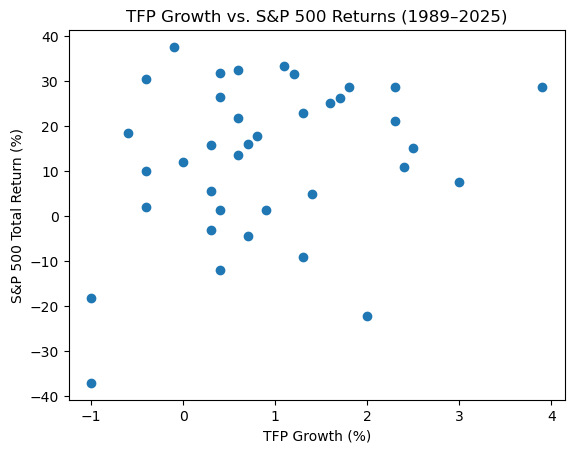

In [31]:
import matplotlib.pyplot as plt

plt.scatter(data["TFP_Growth_Pct"], data["SP500_Return_Pct"])
plt.xlabel("TFP Growth (%)")
plt.ylabel("S&P 500 Total Return (%)")
plt.title("TFP Growth vs. S&P 500 Returns (1989–2025)")
plt.show()

In [32]:
data["TFP_Growth_Pct"].corr(data["SP500_Return_Pct"])

np.float64(0.27288729468187867)

In [33]:
from scipy.stats import pearsonr

r, p_value = pearsonr(
    data["TFP_Growth_Pct"],
    data["SP500_Return_Pct"]
)

print("correaltion：", r)
print("p value：", p_value)

correaltion： 0.2728872946818787
p value： 0.10223374346141893


In [34]:
结果是 **r ≈ 0.273，p ≈ 0.102**。

可以这样解读：

- **r = 0.273**：这 37 年的样本中，TFP 增长率与同年股市回报呈较弱的正线性关系。
- **p = 0.102 > 0.05**：按常用的 5% 显著性水平，**证据不足以拒绝“总体线性相关系数为零”的假设**。

直观地说：假设总体零相关且检验假设成立，得到绝对值至少像 `0.273` 这么大的样本相关系数，概率约为 **10.2%**，并不算特别罕见。

你可以把目前的结论写成：

> 在 1989–2025 年的 37 个年度观测中，TFP 增长率与同年 S&P 500 总回报率呈较弱正相关（r = 0.273），但在 5% 水平上不具有统计显著性（p = 0.102）。

**这不等于证明两者没有关系。** 另外，这是常规 Pearson 检验的初步结果，尚未处理年度数据可能存在的跨年依赖。

SyntaxError: invalid character '≈' (U+2248) (901523277.py, line 1)

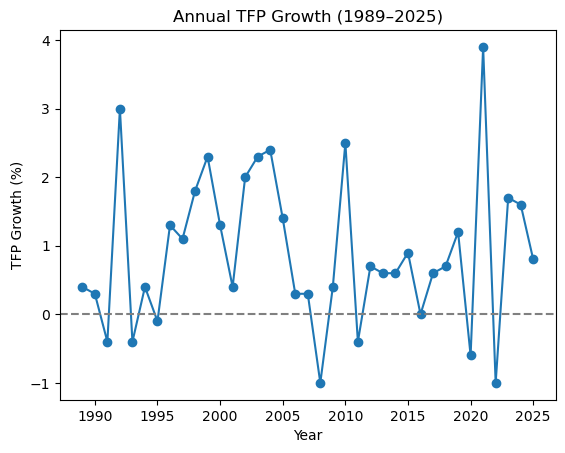

In [ ]:
plt.plot(data["Year"], data["TFP_Growth_Pct"], marker="o")
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("Year")
plt.ylabel("TFP Growth (%)")
plt.title("Annual TFP Growth (1989–2025)")
plt.show()

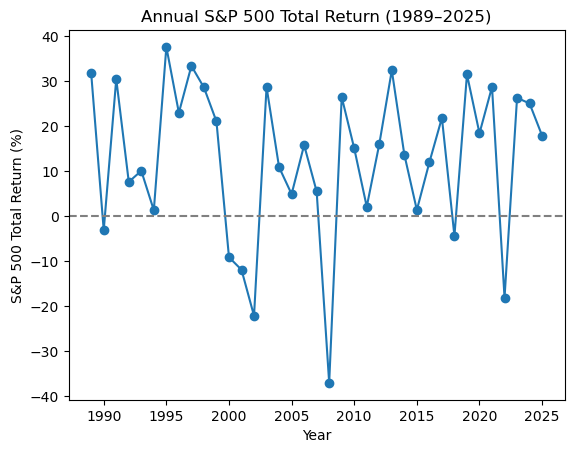

In [ ]:
plt.plot(data["Year"], data["SP500_Return_Pct"], marker="o")
#横轴为年份，纵轴为股市年度总回报率；marker="o" 给每年标一个圆点，并用线连接。
plt.axhline(0, color="gray", linestyle="--")
#plt.axhline(...)：在 0% 处画灰色虚线，线上方表示正回报，下方表示负回报。
plt.xlabel("Year")
plt.ylabel("S&P 500 Total Return (%)")
plt.title("Annual S&P 500 Total Return (1989–2025)")
plt.show()

In [ ]:
tfp_z = (
    data["TFP_Growth_Pct"] - data["TFP_Growth_Pct"].mean()
) / data["TFP_Growth_Pct"].std()

sp500_z = (
    data["SP500_Return_Pct"] - data["SP500_Return_Pct"].mean()
) / data["SP500_Return_Pct"].std()

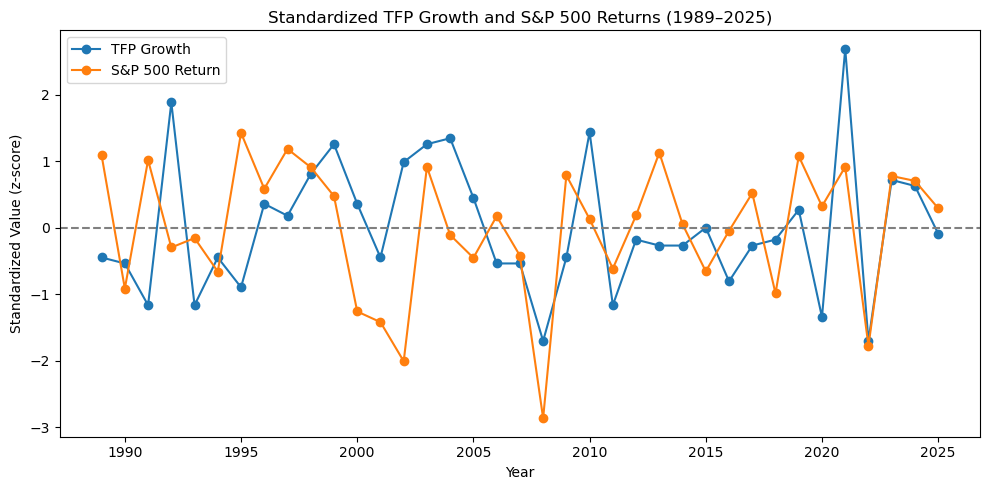

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(data["Year"], tfp_z, label="TFP Growth", marker="o")
plt.plot(data["Year"], sp500_z, label="S&P 500 Return", marker="o")
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("Year")
plt.ylabel("Standardized Value (z-score)")
plt.title("Standardized TFP Growth and S&P 500 Returns (1989–2025)")
plt.legend()
plt.tight_layout()
plt.show()

虚线 0 代表各自的平均值，不代表原始增长率为 0%。 蓝线低于零，表示 TFP 增长低于其平均水平；橙线低于零，表示股市回报低于其平均水平，不一定表示当年下跌。

plt：对“当前绘图区”操作，例如 plt.plot(...)。
ax / axs：明确指定对哪个绘图区操作，多张子图时更清楚。

In [ ]:
data.loc[data["SP500_Return_Pct"].idxmin()]

In [ ]:
#进入简单线性回归：用 TFP 增长率解释同年股市回报率，估计两者关系的幅度。
x = data["TFP_Growth_Pct"]
y = data["SP500_Return_Pct"]

In [ ]:
#拟合这条回归直线
from scipy.stats import linregress

regression = linregress(x, y)

In [ ]:
print("slope：", regression.slope)
print("intercept：", regression.intercept)

slope： 4.251015805634706
intercept： 8.969797530976278


拟合出的回归直线是：

\[
\widehat{\text{股市回报率}} = 8.970 + 4.251 \times \text{TFP增长率}
\]

两列都使用百分数数值，例如 `1` 表示 1%。

**斜率 `4.251`：** 在这个样本的拟合关系中，TFP 增长率每高 **1 个百分点**，同年股市回报率的拟合值就高约 **4.25 个百分点**。这是关联，不能解释为 TFP 导致股市上涨。

**截距 `8.970`：** 当 TFP 增长率为 **0%** 时，模型给出的股市回报率拟合值约为 **8.97%**。

例如，TFP 增长率为 1% 时：

\[
8.970 + 4.251\times1 \approx 13.22\%
\]

这是直线上的拟合值，实际年度回报可能与它相差很大。**斜率为正，也不改变之前“在 5% 水平上不显著”的结论。**

下一步，**查看 \(R^2\)（决定系数），衡量这条直线能解释多少股市回报的样本波动**。

```python
r_squared = regression.rvalue ** 2
print("R²：", r_squared)
```

逐行解释：

- `regression.rvalue`：取出回归结果中的相关系数。
- `** 2`：平方。在我们这个**包含截距的简单线性回归**中，\(R^2\) 等于相关系数的平方。
- `r_squared =`：把计算结果保存为变量 `r_squared`。
- `print(...)`：显示结果。

根据之前的相关系数，预期约为 **`0.0745`，即 7.45%**。它表示这条拟合直线解释了样本中约 7.45% 的股市年度回报变异，**不是预测准确率，也不是因果贡献比例**。

In [ ]:
r_squared = regression.rvalue ** 2
print("R²：", r_squared)

R²： 0.07446747559879445


**\(R^2 \approx 0.0745\)，即 7.45%。**

这表示：在这 37 年的样本中，用 TFP 增长率拟合的这条直线，解释了股市年度回报变异的约 **7.45%**；其余约 **92.55%** 未被这个模型解释。

因此，**单靠同年的 TFP 增长率，这个线性模型的解释能力较有限**。它不代表预测准确率为 7.45%，也不能把剩余部分全部归为随机波动。

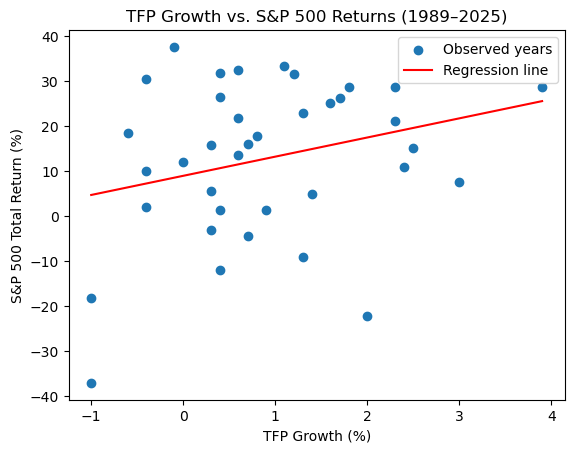

In [ ]:
#把回归直线加到散点图上，直观看它与实际数据的距离。
x_sorted = x.sort_values()
y_fitted = regression.intercept + regression.slope * x_sorted

plt.scatter(x, y, label="Observed years")
plt.plot(x_sorted, y_fitted, color="red", label="Regression line")
plt.xlabel("TFP Growth (%)")
plt.ylabel("S&P 500 Total Return (%)")
plt.title("TFP Growth vs. S&P 500 Returns (1989–2025)")
plt.legend()
plt.show()

逐行解释：
- x_sorted = x.sort_values()：把 TFP 增长率从小到大排列，保存为 x_sorted，方便从左到右画线。
- y_fitted = ...：按照刚才的回归公式 \(a+bx\)，计算每个横坐标对应的拟合回报率。

**回归线画成功了，与之前的计算一致。**

- **红线向上倾斜**：对应正斜率 `4.251`，表示样本中的拟合关系为正。
- **蓝点离红线普遍较远**：实际年度回报与拟合值差异较大，与较低的 \(R^2=7.45\%\) 一致。
- 每个蓝点到红线的**竖直距离**叫作“残差”：
  \[
  残差=实际回报率-拟合回报率
  \]
  点在红线上方，残差为正；下方则为负。

**红线向上不等于关系显著。** 我们之前得到的 \(p=0.102\)，仍表示在常用的 5% 水平上，证据不足以认定总体存在非零线性关系。

In [ ]:
#计算每年的残差，为检查模型拟合情况做准备。
data["SP500_Fitted_Pct"] = regression.intercept + regression.slope * x
data["Residual_Pct"] = y - data["SP500_Fitted_Pct"]

逐行解释：
- 第一行：用回归公式 \(a+bx\) 计算每年的拟合回报率，保存到新列 SP500_Fitted_Pct。这里使用原顺序的 x，与每年的记录对应。
- 第二行：用实际回报率 y 减去拟合回报率，保存到新列 Residual_Pct。残差的单位是百分点。

In [ ]:
display(data[["Year", "SP500_Return_Pct", "SP500_Fitted_Pct", "Residual_Pct"]].head())

,Year,SP500_Return_Pct,SP500_Fitted_Pct,Residual_Pct
0,1989,31.684715,10.670204,21.014511
1,1990,-3.104821,10.245102,-13.349923
2,1991,30.465414,7.269391,23.196022
3,1992,7.620457,21.722845,-14.102388
4,1993,10.077880,7.269391,2.808489


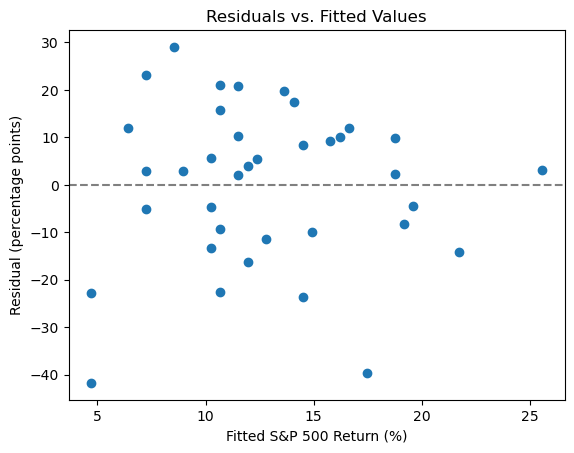

In [ ]:
#画“残差与拟合值”的散点图，检查误差是否呈现明显规律。
plt.scatter(data["SP500_Fitted_Pct"], data["Residual_Pct"])
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("Fitted S&P 500 Return (%)")
plt.ylabel("Residual (percentage points)")
plt.title("Residuals vs. Fitted Values")
plt.show()

**残差图画成功了。** 可以先观察到：

- 点分布在零线上下，**没有清楚的 U 形或倒 U 形**，暂时看不出明显的曲线规律。
- 有两个残差接近 **−40 个百分点**的点，表示模型对这些年份的回报高估了约 40 个百分点，值得后续查看。
- 右侧观测点较少，**仅凭这张图还不能确定误差的波动幅度是否恒定**，不能直接宣布“没有异方差”。

这张图也没有显示年份顺序，因此**不能判断相邻年份的误差是否有关联**。目前它只是初步诊断，不能据此认定模型假设全部成立。

**还在正确的路上，但我带你进入模型细节前，没有把整体位置说明白。** 我们先暂停往下写代码。

你的核心问题是：

> **美国私人企业 TFP 增长较高的年份，S&P 500 的年度总回报是否也较高？**

整个项目的路线，以及目前的位置是：

| 阶段 | 我们做了什么 | 状态 |
|---|---|---|
| 数据预处理 | 筛选 TFP、计算股市年度回报、按年份合并 | 已完成 |
| 探索数据 | 描述统计、时间走势图、标准化图、散点图 | 已完成 |
| 初步分析关系 | Pearson 相关、p 值、简单线性回归 | 已完成 |
| **检查模型** | **查看拟合误差，也就是残差** | **现在这里** |
| 整理结论 | 回答研究问题，说明局限，整理报告 | 尚未完成 |

**现在画残差图，是为了检查那条回归直线是否遗漏了明显规律。** 例如，点如果呈 U 形，说明用直线可能不合适。它是对模型的检查，不是在研究一个新问题。

目前已经得到的核心发现是：

- 同年 TFP 增长与股市回报呈**较弱正相关**：\(r=0.273\)。
- 常规检验的 \(p=0.102\)，在 5% 水平上**不显著**。
- 线性模型的 \(R^2=7.45\%\)，说明**解释能力有限**。

这本身就是有价值的结果，**不需要为了得到显著关系而不断换模型**。

接下来也不应无限增加检查。我们应先对照你的课程项目要求，确定还需要哪些分析，再整理结论。你可以把作业要求或评分标准发给我；在此之前，我们先不继续加代码。

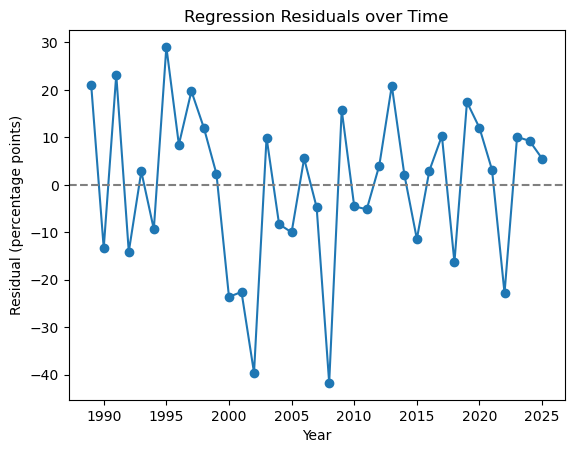

In [ ]:
#按年份画残差图，检查模型是否连续几年都高估或低估回报。这是年度数据需要留意的时间规律。
plt.plot(data["Year"], data["Residual_Pct"], marker="o")
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("Year")
plt.ylabel("Residual (percentage points)")
plt.title("Regression Residuals over Time")
plt.show()

**是的，就你截图展示的 Midterm 范围而言，我们在回归诊断上走得偏深了。** 我应该更早把重点拉回项目交付，抱歉。

不过，截图主要是之前对要求的总结，不能完全替代老师的原始 rubric。根据目前展示的内容，可以这样收缩范围：

| 已做内容 | 如何处理 |
|---|---|
| 数据读取、清洗、年度回报计算、合并与质量检查 | **核心，保留** |
| 描述统计、时间走势图、散点图、相关系数 | **核心，保留** |
| 标准化折线图 | 作为辅助展示，解释清楚用途 |
| 简单线性回归、\(R^2\) | 可选补充 |
| 两张残差图及进一步诊断 | **先停，留在 Notebook 中，不必放进主展示** |

**目前分析已经足以支持一个初步发现：**1989–2025 年，同年 TFP 增长与股市回报的线性关系较弱。没有显著关系也是结果，不需要继续增加模型来寻找显著性。

接下来更值得投入的是：

- 明确 **研究问题和目标用户**。
- 挑选 **2–3 张核心图**，整理发现和局限。
- 做一个有年份筛选等有效交互的 **Streamlit 页面**。
- 整理 README、数据来源和演示流程。

截图中的“低／中／高 TFP 分组比较”也只是一个展示建议，**不能据此当作必做项**。

我们现在可以停止增加统计分析，转向整理已有成果；已经写好的代码不用删。

下一步，**先明确 Streamlit 要回答的问题和服务谁**。现在不写代码。

建议研究问题定为：

> **1989–2025 年，美国私人企业 TFP 年增长率与同年 S&P 500 年度总回报率之间有什么关系？**

目标用户建议定为：

> **希望了解生产率与股市关系、但没有专业金融背景的学生和普通读者。**

这样，页面的任务就清楚了：让用户选择年份范围，查看两者走势和散点图，理解“生产率增长较高，并不意味着同年股市回报一定较高”。

你觉得这个目标用户符合你的想法吗？我们先确定这一点，再开始搭页面。